Dataset: 178 muestras y 13 entradas
Clases de salida: 3
Entradas usadas por la red:
  x1: alcohol
  x2: malic_acid
  x3: ash
  x4: alcalinity_of_ash
  x5: magnesium
  x6: total_phenols
  x7: flavanoids
  x8: nonflavanoid_phenols
  x9: proanthocyanins
  x10: color_intensity
  x11: hue
  x12: od280/od315_of_diluted_wines
  x13: proline

=== Arquitectura de la ANN ===
Entradas: 13
Capas ocultas: 16 y 10 neuronas
Salidas: 3 neuronas
Activacion de capas ocultas: sigmoide
Entrenamiento: iterativo con solver LBFGS

=== Metricas de desempeño ===
Error de clasificacion: 0.037
Accuracy en prueba: 0.963
Precision macro: 0.9666
Recall macro: 0.9619
F1-score macro: 0.9636
Log loss: 0.1677
Accuracy por fold: [0.96 1.   1.   0.96 1.  ]
Accuracy promedio CV: 0.984
Desviacion estandar CV: 0.0196

=== Matriz de confusion ===
[[18  0  0]
 [ 1 20  0]
 [ 0  1 14]]

=== Reporte de clasificacion ===
              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
 

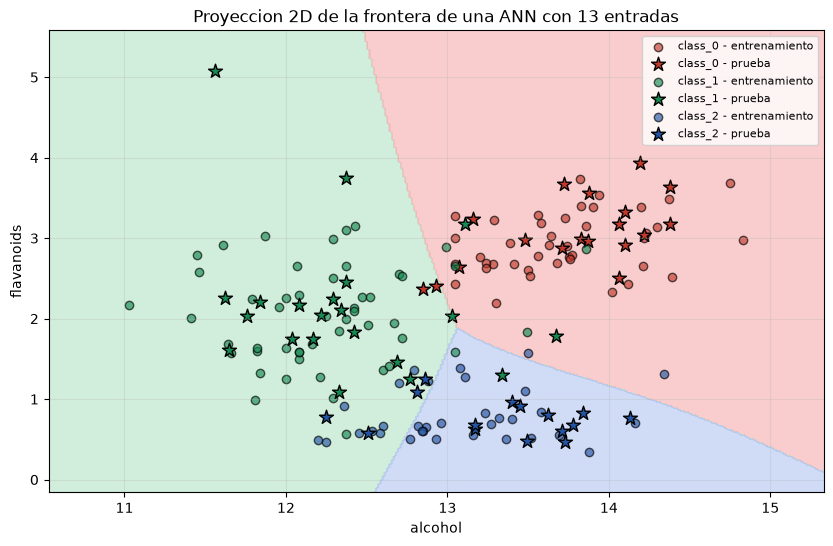

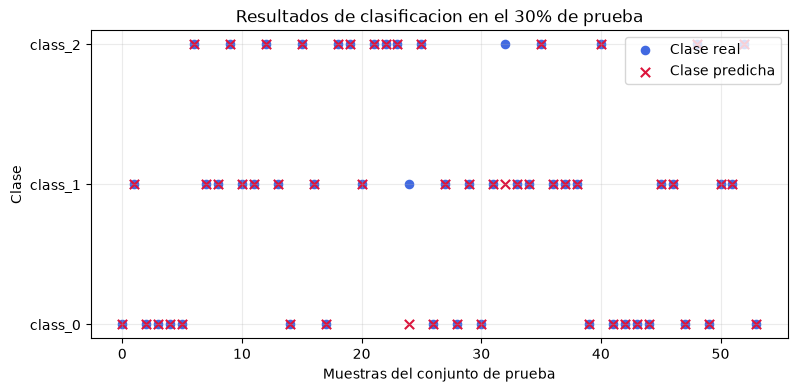

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss,
)
from matplotlib.colors import ListedColormap

np.random.seed(42)

# 1. Cargar el Wine Dataset completo.
wine = load_wine()
X = wine.data
Y = wine.target
nombres_clases = wine.target_names
nombres_caracteristicas = wine.feature_names

print("Dataset:", X.shape[0], "muestras y", X.shape[1], "entradas")
print("Clases de salida:", len(np.unique(Y)))
print("Entradas usadas por la red:")
for indice, nombre in enumerate(nombres_caracteristicas, start=1):
    print(f"  x{indice}: {nombre}")

# 2. Division estratificada 70/30.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42,
    stratify=Y,
)

# 3. ANN: 13 entradas conectadas a las capas ocultas y 3 neuronas de salida.
# activation='logistic' corresponde a la funcion sigmoide.
# solver='lbfgs' ajusta iterativamente los pesos y sesgos.
ann = Pipeline([
    ("escalado", StandardScaler()),
    ("red_neuronal", MLPClassifier(
        hidden_layer_sizes=(16, 10),
        activation="logistic",
        solver="lbfgs",
        alpha=0.001,
        max_iter=3000,
        random_state=42,
    )),
])

# 4. Validacion cruzada sobre el conjunto de entrenamiento.
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_cv = cross_val_score(ann, X_train, y_train, cv=validacion, scoring="accuracy")

# 5. Entrenamiento iterativo final y evaluacion en el 30% reservado.
ann.fit(X_train, y_train)
y_pred = ann.predict(X_test)
y_probabilidad = ann.predict_proba(X_test)

accuracy_test = accuracy_score(y_test, y_pred)
error_test = 1 - accuracy_test
precision_test = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_test = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_test = f1_score(y_test, y_pred, average="macro", zero_division=0)
costo_log_loss = log_loss(y_test, y_probabilidad)

print("\n=== Arquitectura de la ANN ===")
print("Entradas:", X.shape[1])
print("Capas ocultas: 16 y 10 neuronas")
print("Salidas:", len(np.unique(Y)), "neuronas")
print("Activacion de capas ocultas: sigmoide")
print("Entrenamiento: iterativo con solver LBFGS")

print("\n=== Metricas de desempeño ===")
print("Error de clasificacion:", round(error_test, 4))
print("Accuracy en prueba:", round(accuracy_test, 4))
print("Precision macro:", round(precision_test, 4))
print("Recall macro:", round(recall_test, 4))
print("F1-score macro:", round(f1_test, 4))
print("Log loss:", round(costo_log_loss, 4))
print("Accuracy por fold:", np.round(scores_cv, 4))
print("Accuracy promedio CV:", round(scores_cv.mean(), 4))
print("Desviacion estandar CV:", round(scores_cv.std(), 4))

print("\n=== Matriz de confusion ===")
print(confusion_matrix(y_test, y_pred))
print("\n=== Reporte de clasificacion ===")
print(classification_report(y_test, y_pred, target_names=nombres_clases))

# 6. Pesos aprendidos: cada neurona recibe las 13 entradas.
red_neuronal = ann.named_steps["red_neuronal"]
print("=== Dimensiones de los pesos aprendidos ===")
for indice, pesos in enumerate(red_neuronal.coefs_, start=1):
    print(f"Matriz de pesos capa {indice}: {pesos.shape}")

# 7. Frontera 2D como proyeccion de la ANN completa.
# Se varian alcohol y flavanoides; las otras 11 entradas quedan en su media.
indices_frontera = [0, 6]
caracteristicas_frontera = [nombres_caracteristicas[i] for i in indices_frontera]
X_media = X_train.mean(axis=0)

x_min, x_max = X[:, indices_frontera[0]].min() - 0.5, X[:, indices_frontera[0]].max() + 0.5
y_min, y_max = X[:, indices_frontera[1]].min() - 0.5, X[:, indices_frontera[1]].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350),
)
X_malla = np.tile(X_media, (xx.size, 1))
X_malla[:, indices_frontera[0]] = xx.ravel()
X_malla[:, indices_frontera[1]] = yy.ravel()
Z = ann.predict(X_malla).reshape(xx.shape)

colores_fondo = ListedColormap(["#f6b3b3", "#b9e4c9", "#b7c9f2"])
colores_puntos = ["#c0392b", "#168a52", "#2455a4"]

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, cmap=colores_fondo, alpha=0.65)

for clase, color in enumerate(colores_puntos):
    plt.scatter(
        X_train[y_train == clase, indices_frontera[0]],
        X_train[y_train == clase, indices_frontera[1]],
        c=color,
        marker="o",
        edgecolor="black",
        alpha=0.65,
        label=f"{nombres_clases[clase]} - entrenamiento",
    )
    plt.scatter(
        X_test[y_test == clase, indices_frontera[0]],
        X_test[y_test == clase, indices_frontera[1]],
        c=color,
        marker="*",
        s=110,
        edgecolor="black",
        label=f"{nombres_clases[clase]} - prueba",
    )

plt.xlabel(caracteristicas_frontera[0])
plt.ylabel(caracteristicas_frontera[1])
plt.title("Proyeccion 2D de la frontera de una ANN con 13 entradas")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.show()

# 8. Comparacion entre clases reales y predichas.
plt.figure(figsize=(9, 4))
indices = np.arange(len(y_test))
plt.scatter(indices, y_test, label="Clase real", color="royalblue", s=35)
plt.scatter(indices, y_pred, label="Clase predicha", color="crimson", marker="x", s=45)
plt.yticks(range(len(nombres_clases)), nombres_clases)
plt.xlabel("Muestras del conjunto de prueba")
plt.ylabel("Clase")
plt.title("Resultados de clasificacion en el 30% de prueba")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

=== Procesamiento de una muestra ===
Clase real: class_0
Clase predicha: class_0
Activaciones entrada: [ 0.253  0.069  1.144 -0.317  0.063  0.812  1.296 -0.511  2.089  0.289
  0.334  0.833  1.423]
Activaciones capa oculta 1: [0.736 0.999 0.008 0.751 0.073 0.032 0.008 0.856 0.584 0.086 0.068 0.991
 0.405 0.468 0.057 0.757]
Activaciones capa oculta 2: [0.004 0.065 0.04  0.187 0.903 0.008 0.995 0.93  0.149 0.984]
Probabilidades de salida: [1. 0. 0.]


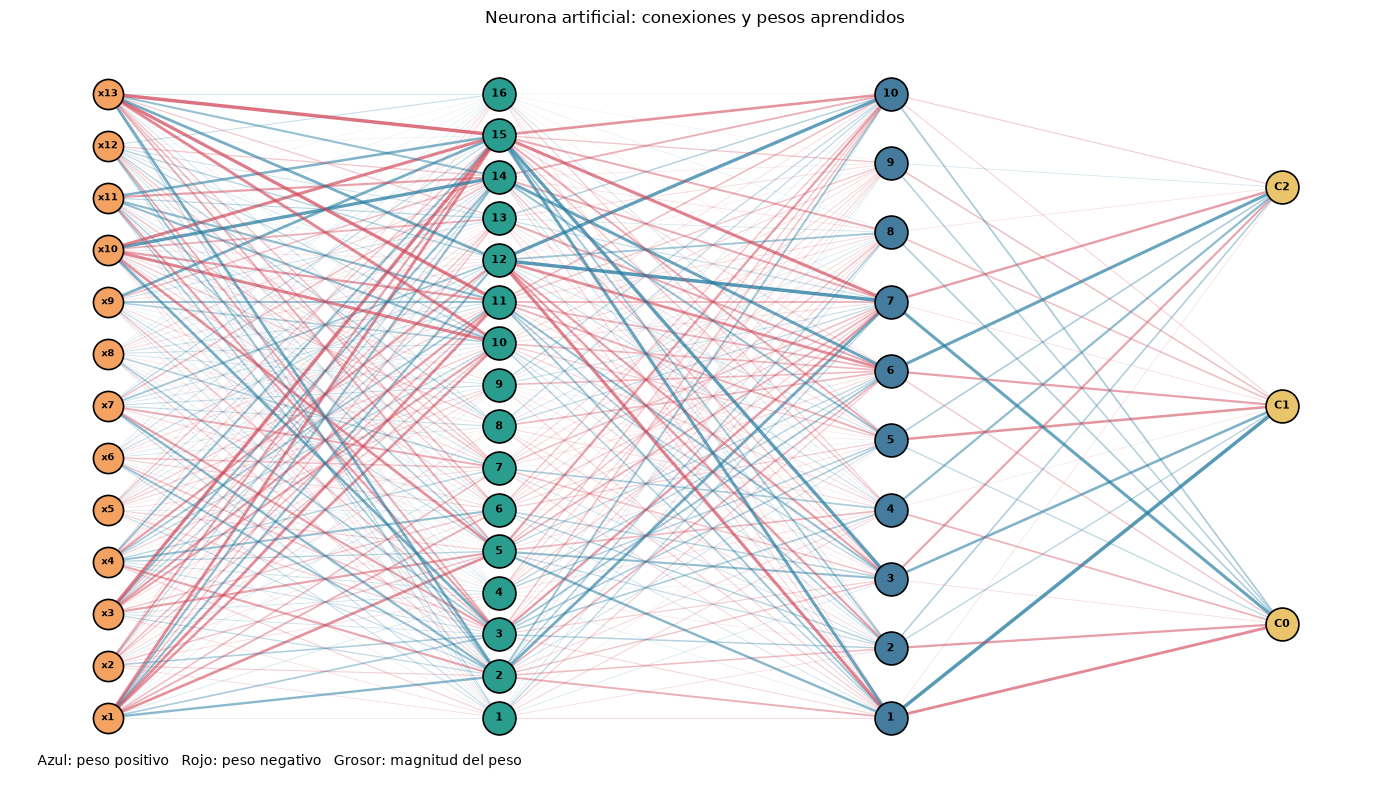

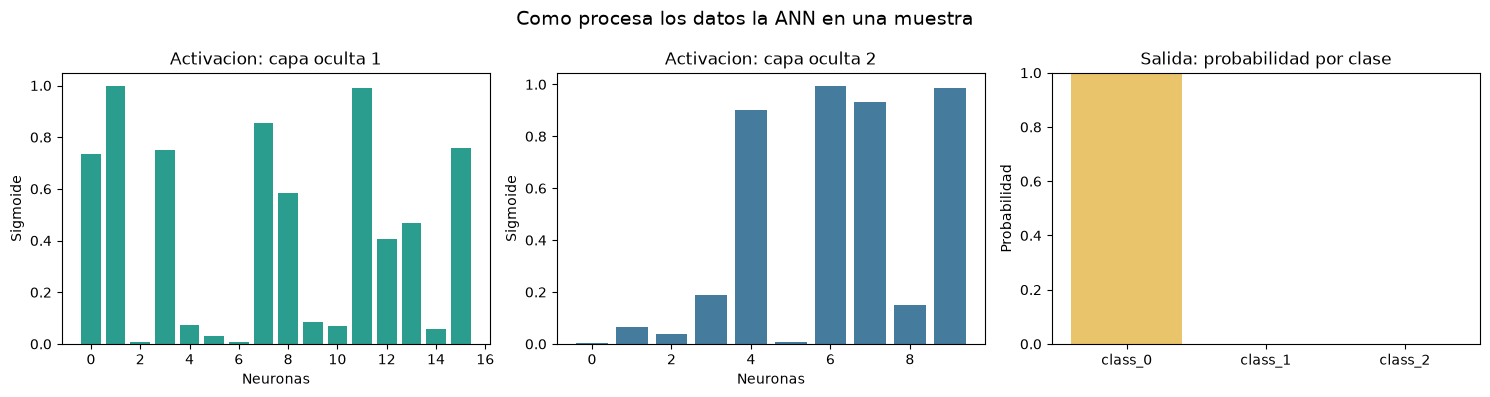

In [ ]:
# 9. Visualizar las neuronas y su procesamiento interno.
# Se inspecciona una muestra del conjunto de prueba.
muestra = X_test[0]
clase_real = y_test[0]

# Transformar la muestra con el mismo escalado usado durante el entrenamiento.
escalador = ann.named_steps["escalado"]
red = ann.named_steps["red_neuronal"]
muestra_escalada = escalador.transform(muestra.reshape(1, -1))

# Calcular las activaciones de cada capa paso a paso.
activacion_entrada = muestra_escalada.ravel()
z_oculta_1 = activacion_entrada @ red.coefs_[0] + red.intercepts_[0]
activacion_oculta_1 = 1 / (1 + np.exp(-np.clip(z_oculta_1, -500, 500)))
z_oculta_2 = activacion_oculta_1 @ red.coefs_[1] + red.intercepts_[1]
activacion_oculta_2 = 1 / (1 + np.exp(-np.clip(z_oculta_2, -500, 500)))
z_salida = activacion_oculta_2 @ red.coefs_[2] + red.intercepts_[2]
probabilidades = red.predict_proba(muestra_escalada)[0]
clase_predicha = np.argmax(probabilidades)

print("=== Procesamiento de una muestra ===")
print("Clase real:", nombres_clases[clase_real])
print("Clase predicha:", nombres_clases[clase_predicha])
print("Activaciones entrada:", np.round(activacion_entrada, 3))
print("Activaciones capa oculta 1:", np.round(activacion_oculta_1, 3))
print("Activaciones capa oculta 2:", np.round(activacion_oculta_2, 3))
print("Probabilidades de salida:", np.round(probabilidades, 3))

# Diagrama de la red: grosor y color de las conexiones representan los pesos.
capas = [13, 16, 10, 3]
posiciones_x = np.arange(len(capas))
posiciones_y = [
    np.linspace(-1.0, 1.0, capas[0]),
    np.linspace(-1.0, 1.0, capas[1]),
    np.linspace(-1.0, 1.0, capas[2]),
    np.linspace(-0.7, 0.7, capas[3]),
]

fig, ax = plt.subplots(figsize=(14, 8))
colores_conexion = ["#d1495b", "#247ba0"]

for indice_capa, matriz_pesos in enumerate(red.coefs_):
    pesos_normalizados = np.abs(matriz_pesos) / (np.max(np.abs(matriz_pesos)) + 1e-9)
    for origen in range(matriz_pesos.shape[0]):
        for destino in range(matriz_pesos.shape[1]):
            peso = matriz_pesos[origen, destino]
            color = colores_conexion[1] if peso >= 0 else colores_conexion[0]
            ax.plot(
                [posiciones_x[indice_capa], posiciones_x[indice_capa + 1]],
                [posiciones_y[indice_capa][origen], posiciones_y[indice_capa + 1][destino]],
                color=color,
                alpha=0.12 + 0.65 * pesos_normalizados[origen, destino],
                linewidth=0.3 + 2.2 * pesos_normalizados[origen, destino],
                zorder=1,
            )

colores_nodos = ["#f4a261", "#2a9d8f", "#457b9d", "#e9c46a"]
for indice_capa, cantidad_neuronas in enumerate(capas):
    ax.scatter(
        np.full(cantidad_neuronas, posiciones_x[indice_capa]),
        posiciones_y[indice_capa],
        s=470 if indice_capa == 0 else 560,
        color=colores_nodos[indice_capa],
        edgecolor="black",
        linewidth=1.2,
        zorder=2,
    )

    for indice_neurona, posicion_y in enumerate(posiciones_y[indice_capa]):
        if indice_capa == 0:
            etiqueta = f"x{indice_neurona + 1}"
        elif indice_capa == len(capas) - 1:
            etiqueta = f"C{indice_neurona}"
        else:
            etiqueta = str(indice_neurona + 1)
        ax.text(
            posiciones_x[indice_capa],
            posicion_y,
            etiqueta,
            ha="center",
            va="center",
            fontsize=7 if indice_capa == 0 else 8,
            fontweight="bold",
            zorder=3,
        )

ax.set_xticks(posiciones_x)
ax.set_xticklabels(["Entrada\n13 variables", "Oculta 1\n16 neuronas", "Oculta 2\n10 neuronas", "Salida\n3 clases"])
ax.set_title("Neurona artificial: conexiones y pesos aprendidos")
ax.set_xlim(-0.25, len(capas) - 1 + 0.25)
ax.set_ylim(-1.2, 1.2)
ax.axis("off")
ax.text(0.02, 0.02, "Azul: peso positivo   Rojo: peso negativo   Grosor: magnitud del peso", transform=ax.transAxes, fontsize=10)
plt.tight_layout()
plt.show()

# Activaciones internas y probabilidades de salida para la misma muestra.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(np.arange(len(activacion_oculta_1)), activacion_oculta_1, color="#2a9d8f")
axes[0].set_title("Activacion: capa oculta 1")
axes[0].set_xlabel("Neuronas")
axes[0].set_ylabel("Sigmoide")

axes[1].bar(np.arange(len(activacion_oculta_2)), activacion_oculta_2, color="#457b9d")
axes[1].set_title("Activacion: capa oculta 2")
axes[1].set_xlabel("Neuronas")
axes[1].set_ylabel("Sigmoide")

axes[2].bar(nombres_clases, probabilidades, color="#e9c46a")
axes[2].set_title("Salida: probabilidad por clase")
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("Probabilidad")

fig.suptitle("Como procesa los datos la ANN en una muestra", fontsize=14)
plt.tight_layout()
plt.show()

# Clasificacion del Wine Dataset con una ANN

## 1. ¿Que es la base de datos?

El **Wine Dataset** es un conjunto de datos clasico incluido en `scikit-learn`. Contiene mediciones quimicas realizadas sobre vinos pertenecientes a tres variedades diferentes.

Cada fila representa una muestra de vino y cada columna describe una propiedad quimica de esa muestra. La base se utiliza para estudiar problemas de **clasificacion multiclase**, porque cada vino pertenece a una de tres categorias.

### Caracteristicas generales

- **178 muestras de vino**.
- **13 variables predictoras**.
- **3 clases** de vino.
- No es un problema de regresion: la salida es una categoria, no un numero continuo.
- Las variables tienen escalas diferentes, por lo que es conveniente estandarizarlas antes de entrenar una ANN.

## 2. ¿Que almacena cada registro?

Cada registro almacena informacion quimica y fisica relacionada con el vino. Las 13 variables son:

| Variable | Descripcion general |
|---|---|
| `alcohol` | Concentracion de alcohol |
| `malic_acid` | Cantidad de acido malico |
| `ash` | Cantidad de ceniza |
| `alcalinity_of_ash` | Alcalinidad de la ceniza |
| `magnesium` | Concentracion de magnesio |
| `total_phenols` | Fenoles totales |
| `flavanoids` | Concentracion de flavonoides |
| `nonflavanoid_phenols` | Fenoles no flavonoides |
| `proanthocyanins` | Proantocianidinas |
| `color_intensity` | Intensidad del color |
| `hue` | Matiz o tonalidad del vino |
| `od280/od315_of_diluted_wines` | Medida de absorbancia optica |
| `proline` | Concentracion de prolina |

La variable objetivo es `target`, que identifica la clase del vino con los valores `0`, `1` y `2`.

## 3. ¿Que se busca en el ejercicio?

El objetivo es entrenar una **red neuronal artificial (ANN)** para que aprenda a clasificar correctamente las tres clases del Wine Dataset.

El programa debe:

1. cargar el dataset,
2. seleccionar las variables de entrada,
3. separar los datos en entrenamiento y prueba usando una division 70/30,
4. estandarizar las variables,
5. entrenar una ANN con activacion sigmoide,
6. aplicar validacion cruzada sobre el conjunto de entrenamiento,
7. evaluar el modelo con datos que no vio durante el entrenamiento,
8. mostrar los errores, la matriz de confusion y el reporte de clasificacion,
9. representar graficamente la frontera de decision.

## 4. ¿Por que se usan dos variables?

El dataset tiene 13 variables, pero una frontera de decision solo puede visualizarse directamente en dos dimensiones. Por eso el ejercicio utiliza `alcohol` y `flavanoids` como variables de entrada para construir una grafica comprensible.

Esto permite observar:

- donde se ubica cada clase,
- que regiones asigna la ANN a cada categoria,
- en que zonas pueden ocurrir confusiones,
- como los puntos de prueba se comportan frente a la frontera aprendida.

Usar dos variables facilita la visualizacion, aunque puede reducir la informacion disponible para clasificar. En una aplicacion real se podrian utilizar las 13 variables y visualizar los resultados con otras tecnicas, como PCA.

## 5. Division 70/30

Los datos se dividen de la siguiente forma:

- **70% para entrenamiento:** la ANN aprende sus pesos a partir de estos datos.
- **30% para prueba:** se reservan para medir la capacidad de generalizacion.

La division es estratificada, lo que significa que se intenta conservar una proporcion similar de las tres clases en ambos grupos.

El conjunto de prueba no debe utilizarse para ajustar los pesos. Si se usa durante el entrenamiento, la evaluacion puede parecer mejor de lo que realmente es.

## 6. Estandarizacion

Las variables tienen unidades y rangos diferentes. Por ejemplo, `alcohol` y `magnesium` no tienen la misma escala. La estandarizacion transforma cada variable para que tenga aproximadamente media cero y desviacion estandar uno.

Esto ayuda a que la ANN:

- entrene de forma mas estable,
- evite que una variable domine por tener valores numericamente mayores,
- encuentre los pesos con mayor facilidad.

La estandarizacion se incorpora en un `Pipeline` junto con la ANN para evitar aplicar transformaciones de forma incorrecta.

## 7. ¿Que es la ANN utilizada?

La red neuronal tiene:

- una capa de entrada con dos variables,
- dos capas ocultas con neuronas artificiales,
- una capa de salida para las tres clases,
- activacion sigmoide en las capas ocultas.

Cada neurona calcula una suma ponderada de sus entradas, agrega un sesgo y aplica una funcion de activacion. Durante el entrenamiento, los pesos se ajustan para reducir el error de clasificacion.

En `scikit-learn`, la activacion sigmoide se indica mediante:

```python
activation="logistic"
```

La ANN produce probabilidades para cada clase y selecciona la clase con mayor probabilidad.

## 8. Validacion cruzada

La validacion cruzada utiliza 5 particiones estratificadas del conjunto de entrenamiento. En cada repeticion:

1. cuatro particiones se usan para entrenar,
2. una particion se usa para validar,
3. se registra el accuracy,
4. el proceso se repite cambiando la particion de validacion.

El promedio de los cinco resultados permite saber si el rendimiento es estable. La desviacion estandar indica cuanto cambia el resultado entre particiones.

La validacion cruzada se realiza solo sobre el 70% de entrenamiento. El 30% de prueba se conserva aparte para la evaluacion final.

## 9. Funcion de activacion sigmoide

La sigmoide transforma un valor interno en un numero entre 0 y 1. Su forma general es:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Se utiliza en este ejercicio porque permite que las neuronas ocultas representen relaciones no lineales. Para clasificacion multiclase, la salida final se interpreta mediante las probabilidades de las tres clases.

## 10. Metricas y resultados

El notebook muestra varias formas de evaluar la ANN:

- **Accuracy:** proporcion de predicciones correctas.
- **Error de clasificacion:** `1 - accuracy`.
- **Log loss:** penaliza las predicciones incorrectas y especialmente aquellas realizadas con mucha confianza.
- **Precision:** de las predicciones de una clase, cuantas fueron correctas.
- **Recall:** de los ejemplos reales de una clase, cuantos fueron encontrados.
- **F1-score:** combina precision y recall.
- **Matriz de confusion:** muestra aciertos y confusiones entre las tres clases.

No se debe observar solo el accuracy. La matriz de confusion ayuda a identificar si una clase se confunde mas que las otras.

## 11. Frontera de decision

La frontera de decision es la separacion aprendida por la ANN entre las regiones correspondientes a las distintas clases.

En la grafica:

- cada color de fondo representa la clase que la ANN predice en esa region,
- los circulos representan datos de entrenamiento,
- las estrellas representan datos de prueba,
- las zonas donde los colores se encuentran son regiones de mayor dificultad.

La frontera no es una regla programada manualmente. Es el resultado de los pesos aprendidos por la red neuronal.

## 12. Antes de interpretar el resultado

Una buena evaluacion debe considerar:

- si el accuracy de prueba es parecido al promedio de cross-validation,
- si la desviacion estandar de los folds es baja,
- si existe una diferencia grande entre entrenamiento y prueba,
- que clases aparecen con mas errores,
- si la frontera se adapta demasiado a los datos de entrenamiento.

Una diferencia muy grande entre entrenamiento y prueba puede indicar sobreajuste. Un resultado bajo en ambos conjuntos puede indicar que el modelo es demasiado simple o que las variables seleccionadas no contienen suficiente informacion.

## 13. Aplicaciones y limitaciones

Un clasificador de este tipo puede servir como ejemplo de apoyo para:

- identificar categorias de productos a partir de mediciones,
- clasificar muestras quimicas,
- reconocer grupos de pacientes a partir de indicadores,
- separar tipos de materiales con propiedades medibles.

Sin embargo, este ejercicio no representa por si solo un sistema de certificacion de calidad del vino. Para una aplicacion real se necesitarian mas muestras, validacion externa, control de calidad de las mediciones y analisis de las consecuencias de los errores.

## 14. Resumen previo a la programacion

Antes de ejecutar el codigo se debe tener claro que:

- las entradas son mediciones quimicas,
- la salida es una de tres clases,
- se usa una division estratificada 70/30,
- la validacion cruzada se aplica al entrenamiento,
- las variables se estandarizan,
- la ANN usa sigmoide en las capas ocultas,
- el rendimiento se mide con varias metricas,
- la frontera se dibuja usando dos variables para facilitar la interpretacion.

## 15. Diferencia entre datos de entrenamiento y prueba

### Datos de entrenamiento

Son el 70% de las muestras utilizadas para que la ANN aprenda. Durante esta etapa, la red modifica sus pesos y sesgos para encontrar relaciones entre las 13 mediciones quimicas y la clase del vino.

La red puede observar las entradas y sus clases reales muchas veces durante el entrenamiento. Estos datos sirven para ajustar el modelo, no para demostrar por si solos que el modelo funciona con datos nuevos.

### Datos de prueba

Son el 30% de las muestras que se mantienen separadas durante el entrenamiento. La red no debe usarlas para modificar sus pesos. Al final se utilizan para comprobar si el modelo generaliza correctamente a vinos que no habia visto.

**Analogia:** los datos de entrenamiento son los ejercicios que un estudiante usa para estudiar; los datos de prueba son el examen final. Si el estudiante ve las respuestas del examen antes de presentarlo, la nota ya no mide su capacidad real.

### ¿Que ocurre si se modifican los valores?

Los cambios en los datos pueden modificar los pesos aprendidos, las fronteras de decision y las metricas:

- **Cambiar valores de las entradas:** modifica las caracteristicas quimicas de un vino. La red puede producir otra probabilidad y cambiar la clase predicha.
- **Cambiar una etiqueta `y`:** indica que la clase correcta de una muestra es diferente. La red intentara aprender esa nueva relacion y puede empeorar si la etiqueta es incorrecta.
- **Agregar ruido:** hace que los datos sean menos claros y normalmente aumenta el error.
- **Reducir el numero de muestras:** puede hacer que el modelo aprenda patrones poco confiables.
- **Cambiar la proporcion 70/30:** modifica la cantidad de datos disponibles para aprender y para evaluar.
- **Cambiar `random_state`:** produce otra particion. Las metricas pueden variar porque el conjunto de prueba contiene muestras diferentes.
- **Modificar `hidden_layer_sizes`:** cambia la capacidad de la red. Muy pocos nodos pueden producir subajuste; demasiados pueden producir sobreajuste.

### Como interpretar los cambios

Si el accuracy de entrenamiento es muy alto pero el accuracy de prueba baja, puede existir **sobreajuste**: la red memorizo los ejemplos de entrenamiento y no aprendio una regla general.

Si ambos accuracy son bajos, puede existir **subajuste**, pocos datos utiles, variables poco informativas o una configuracion insuficiente de la red.

Si el accuracy de entrenamiento y prueba son parecidos y altos, y la validacion cruzada tambien es estable, existe evidencia de que el modelo generaliza mejor.

Es importante modificar una cosa a la vez y volver a comparar:

1. accuracy,
2. error de clasificacion,
3. precision, recall y F1-score,
4. log loss,
5. matriz de confusion,
6. promedio y desviacion estandar de cross-validation.

## 16. ¿Como funcionan las redes neuronales?

Una red neuronal artificial procesa la informacion de izquierda a derecha. Cada capa recibe valores de la capa anterior, realiza calculos y envia nuevos valores a la siguiente capa.

El recorrido general es:

```text
Datos de entrada -> pesos y sesgos -> capas ocultas -> capa de salida -> clase predicha
```

Durante el entrenamiento, la red compara la prediccion con la clase real. Luego ajusta sus pesos para disminuir el error. Este proceso se repite de forma iterativa en muchas actualizaciones.

## 17. ¿Que es cada nodo?

Cada circulo del diagrama representa una **neurona artificial** o nodo. Un nodo recibe valores, calcula una suma ponderada, agrega su sesgo y aplica una funcion de activacion.

Para una neurona, el calculo conceptual es:

$$
z = w_1x_1 + w_2x_2 + ... + w_nx_n + bias$$

Luego se aplica la sigmoide:

$$
a = \frac{1}{1 + e^{-z}}$$

El resultado `a` se convierte en una entrada para los nodos de la siguiente capa.

## 18. ¿Que significa cada valor?

- **Entrada `x`:** una medicion del vino, como alcohol o magnesio.
- **Peso `w`:** indica cuanto influye una entrada en una conexion. Un peso positivo aumenta la suma; uno negativo la reduce.
- **Bias o sesgo:** permite desplazar la respuesta de la neurona.
- **Suma `z`:** combinacion de entradas multiplicadas por sus pesos y el sesgo.
- **Activacion `a`:** resultado que la neurona envia a la siguiente capa.
- **Probabilidad de salida:** confianza estimada para cada clase.

Los valores que aparecen en las barras de activacion muestran que tan activa esta cada neurona para una muestra especifica. Un valor cercano a 1 indica una activacion alta y uno cercano a 0 indica una activacion baja en una neurona sigmoide.

## 19. ¿Que son las lineas o vertices?

Las lineas que conectan los nodos representan conexiones entre neuronas. En terminologia de grafos, pueden llamarse aristas; en una red neuronal se conocen normalmente como conexiones.

Cada conexion tiene un peso aprendido:

- una linea azul representa un peso positivo,
- una linea roja representa un peso negativo,
- una linea mas gruesa representa un peso con mayor magnitud,
- una linea tenue representa un peso cercano a cero.

La conexion no es un dato adicional. Es el camino por el cual viaja la informacion transformada desde una neurona hacia otra.

## 20. ¿Por donde comienza y por donde termina?

La red comienza en la **capa de entrada**, formada por las 13 mediciones del vino. La primera entrada corresponde a `alcohol`, la segunda a `malic_acid` y asi sucesivamente hasta `proline`.

Despues, los valores pasan por:

```text
13 entradas
    -> 16 neuronas de la capa oculta 1
    -> 10 neuronas de la capa oculta 2
    -> 3 neuronas de salida
```

La red termina en las tres neuronas de salida. Cada una representa una clase del vino. La salida con mayor probabilidad se convierte en la prediccion final.

## 21. ¿Por que hay tantos nodos?

Las 13 entradas son necesarias porque cada muestra tiene 13 caracteristicas quimicas. No todas las entradas tienen la misma influencia, pero la red necesita recibirlas para aprender sus combinaciones.

Las capas ocultas tienen varios nodos porque una sola neurona solo puede aprender una transformacion limitada. Al combinar muchas neuronas, la red puede detectar diferentes patrones:

- relaciones entre alcohol y fenoles,
- combinaciones entre color e intensidad,
- interacciones entre flavonoides y prolina,
- separaciones no lineales entre clases.

En este ejercicio hay 16 y 10 neuronas ocultas como una capacidad intermedia para aprender patrones sin hacer la red innecesariamente grande.

- **Muy pocos nodos:** la red puede ser demasiado simple y cometer muchos errores.
- **Demasiados nodos:** puede memorizar el entrenamiento, volverse mas lenta y sobreajustarse.
- **Cantidad adecuada:** aprende patrones utiles y generaliza mejor.

La cantidad de nodos no se interpreta como una cantidad de categorias. Las tres categorias estan representadas por las tres neuronas de salida; los nodos ocultos son detectores internos de patrones.


In [5]:
print("=== Fin del programa ===")

=== Fin del programa ===


## Ejercicio adicional: clasificacion con MLP

En esta nueva actividad se entrena un modelo `MLPClassifier` independiente para clasificar el Wine Dataset usando las 13 variables de entrada y las tres clases de salida.

El modelo utiliza una capa oculta diferente a la red anterior para comparar si la arquitectura y el metodo de optimizacion cambian el resultado. Se conserva la misma division 70/30, de modo que la comparacion sea justa.

Se analizaran:

- matriz de confusion del nuevo MLP,
- accuracy, precision, recall y F1-score,
- log loss,
- comparacion directa contra el modelo anterior,
- diferencias entre los errores de ambos modelos.

La comparacion no elimina el experimento anterior. Ambos modelos se entrenan y evaluan sobre los mismos conjuntos `X_train`, `X_test`, `y_train` y `y_test`.

=== Nuevo modelo MLP ===
Accuracy: 0.9630
Error: 0.0370
Precision macro: 0.9616
Recall macro: 0.9683
F1 macro: 0.9636
Log loss: 0.3782

=== Comparacion con el modelo previo ===
Accuracy: previo=0.9630 | MLP=0.9630
Error: previo=0.0370 | MLP=0.0370
Precision macro: previo=0.9666 | MLP=0.9616
Recall macro: previo=0.9619 | MLP=0.9683
F1 macro: previo=0.9636 | MLP=0.9636
Log loss: previo=0.1677 | MLP=0.3782

=== Matriz de confusion del nuevo MLP ===
[[18  0  0]
 [ 1 19  1]
 [ 0  0 15]]

=== Reporte de clasificacion del nuevo MLP ===
              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.90      0.95        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



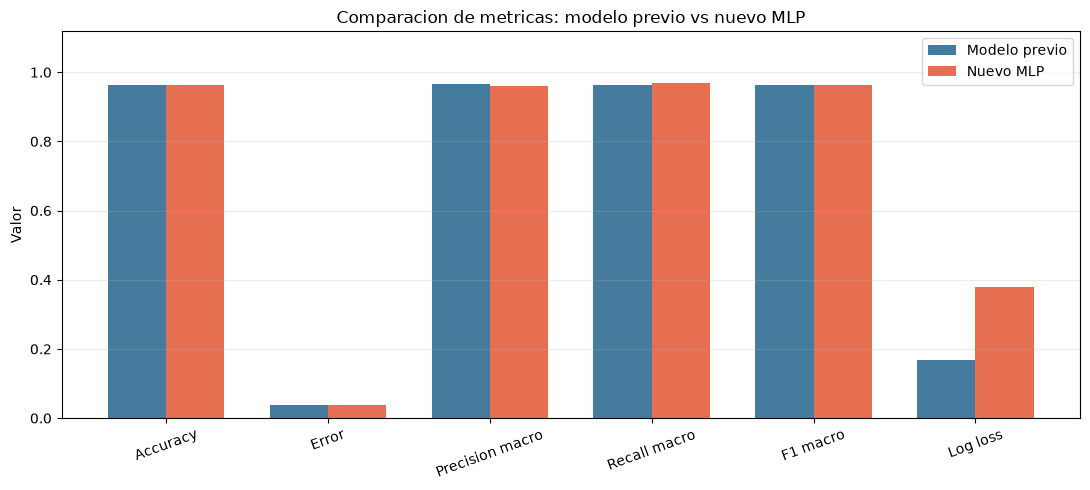

C:\Users\peral\AppData\Local\Temp\ipykernel_22008\3699211832.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


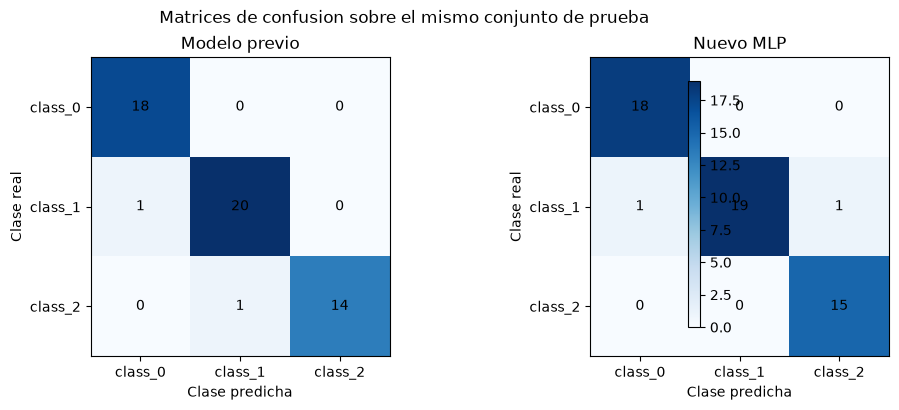

In [6]:
# Ejercicio adicional: entrenar y evaluar un MLP independiente.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss,
)

# Este MLP usa las 13 entradas y una arquitectura diferente a la anterior.
mlp_comparacion = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(12, 8),
        activation="logistic",
        solver="adam",
        learning_rate_init=0.01,
        max_iter=3000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=40,
        random_state=7,
    )),
])

# Entrenamiento iterativo con los mismos datos usados por el modelo anterior.
mlp_comparacion.fit(X_train, y_train)
y_pred_mlp = mlp_comparacion.predict(X_test)
y_probabilidad_mlp = mlp_comparacion.predict_proba(X_test)

# Metricas del nuevo modelo.
metricas_mlp = {
    "Accuracy": accuracy_score(y_test, y_pred_mlp),
    "Error": 1 - accuracy_score(y_test, y_pred_mlp),
    "Precision macro": precision_score(y_test, y_pred_mlp, average="macro", zero_division=0),
    "Recall macro": recall_score(y_test, y_pred_mlp, average="macro", zero_division=0),
    "F1 macro": f1_score(y_test, y_pred_mlp, average="macro", zero_division=0),
    "Log loss": log_loss(y_test, y_probabilidad_mlp),
}

# Metricas del modelo previo, que tambien se conservaron y ya fueron entrenadas.
metricas_previas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Error": 1 - accuracy_score(y_test, y_pred),
    "Precision macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Log loss": log_loss(y_test, y_probabilidad),
}

print("=== Nuevo modelo MLP ===")
for metrica, valor in metricas_mlp.items():
    print(f"{metrica}: {valor:.4f}")

print("\n=== Comparacion con el modelo previo ===")
for metrica in metricas_previas:
    print(f"{metrica}: previo={metricas_previas[metrica]:.4f} | MLP={metricas_mlp[metrica]:.4f}")

print("\n=== Matriz de confusion del nuevo MLP ===")
print(confusion_matrix(y_test, y_pred_mlp))

print("\n=== Reporte de clasificacion del nuevo MLP ===")
print(classification_report(y_test, y_pred_mlp, target_names=nombres_clases))

# Tabla grafica de comparacion entre ambos modelos.
metricas_comparacion = list(metricas_previas.keys())
valores_previos = [metricas_previas[metrica] for metrica in metricas_comparacion]
valores_mlp = [metricas_mlp[metrica] for metrica in metricas_comparacion]

posiciones = np.arange(len(metricas_comparacion))
ancho = 0.36

plt.figure(figsize=(11, 5))
plt.bar(posiciones - ancho / 2, valores_previos, ancho, label="Modelo previo", color="#457b9d")
plt.bar(posiciones + ancho / 2, valores_mlp, ancho, label="Nuevo MLP", color="#e76f51")
plt.xticks(posiciones, metricas_comparacion, rotation=20)
plt.ylabel("Valor")
plt.title("Comparacion de metricas: modelo previo vs nuevo MLP")
plt.ylim(0, max(max(valores_previos), max(valores_mlp)) + 0.15)
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Matrices de confusion lado a lado.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
matriz_previa = confusion_matrix(y_test, y_pred)
matriz_mlp = confusion_matrix(y_test, y_pred_mlp)

for eje, matriz, titulo in zip(
    axes,
    [matriz_previa, matriz_mlp],
    ["Modelo previo", "Nuevo MLP"],
):
    imagen = eje.imshow(matriz, cmap="Blues")
    eje.set_title(titulo)
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
    eje.set_xticks(range(len(nombres_clases)), nombres_clases)
    eje.set_yticks(range(len(nombres_clases)), nombres_clases)
    for fila in range(matriz.shape[0]):
        for columna in range(matriz.shape[1]):
            eje.text(columna, fila, matriz[fila, columna], ha="center", va="center")

fig.colorbar(imagen, ax=axes.ravel().tolist(), shrink=0.8)
fig.suptitle("Matrices de confusion sobre el mismo conjunto de prueba")
plt.tight_layout()
plt.show()